<a href="https://colab.research.google.com/github/madhan-4413/ML-Algorithms/blob/main/Wind%20Energy%20Efficiency%20Models/Model_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wind Turbine Performance & Target Parameter Prediction

This notebook demonstrates a complete end-to-end Machine Learning pipeline to analyze and predict target parameters of wind turbines based on operational and weather data metrics.

## 1. Project Purpose
The goal of this project is to model and predict the target operational parameter (`Target`) of wind turbines using physical and electrical metrics (e.g., wind speed, temperatures, speeds, and power metrics). Since multicollinearity is expected in sensor data, a core objective is to identify and remove highly correlated features using the Variance Inflation Factor (VIF) to ensure robust model interpretation and generalization before fitting regression models such as **Linear Regression**, **Decision Trees**, and **Random Forests**.

**Data set link:-** https://drive.google.com/file/d/1jtHvctY-zYBzxAhkiQG3neLxSlAzF80X/view?usp=sharing

## 2. Environment Setup & Data Loading
We start by importing the essential data science, visualization, and machine learning libraries, and loading the training dataset.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import *

In [ ]:
df=pd.read_csv('/content/train (1).csv')

## 3. Exploratory Data Analysis (EDA)
Let's understand the structural layout, numerical distribution, and potential outliers of our features using basic statistics and boxplots.

In [ ]:
df.head()

,timestamp,active_power_calculated_by_converter,active_power_raw,ambient_temperature,generator_speed,generator_winding_temp_max,grid_power10min_average,nc1_inside_temp,nacelle_temp,reactice_power_calculated_by_converter,reactive_power,wind_direction_raw,wind_speed_raw,wind_speed_turbulence,turbine_id,Target
0,2021-02-19 20:18:00,816.636759,834.917206,31.694380,1159.616602,65.954214,917.897085,31.881972,31.504713,141.457644,165.501518,280.864782,7.057000,0.544082,Turbine_108,47.582787
1,2021-04-27 04:55:00,419.107829,421.050873,12.894948,928.747996,59.571319,445.554250,32.423705,32.755770,89.186457,113.835236,299.552460,5.474937,0.469031,Turbine_18,46.070328
2,2021-01-25 06:26:00,1303.530558,1337.566142,16.648388,1201.219775,61.270498,1364.716003,11.446849,18.332985,230.622309,281.452253,84.960106,8.092457,0.622318,Turbine_105,39.989236
3,2021-10-30 03:47:00,61.494872,53.481008,28.388141,769.806122,40.674348,14.324897,34.253204,32.662889,66.211015,75.017531,87.261119,4.071032,0.760719,Turbine_15,46.056587
4,2021-03-15 00:39:00,593.514364,611.659108,31.519527,1046.916768,64.341763,599.020172,32.405586,31.466387,137.163938,160.202421,313.724818,6.357943,0.346068,Turbine_01,54.346095


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 909604 entries, 0 to 909603
Data columns (total 16 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   timestamp                               909604 non-null  object 
 1   active_power_calculated_by_converter    909604 non-null  float64
 2   active_power_raw                        909604 non-null  float64
 3   ambient_temperature                     909604 non-null  float64
 4   generator_speed                         909604 non-null  float64
 5   generator_winding_temp_max              909604 non-null  float64
 6   grid_power10min_average                 909604 non-null  float64
 7   nc1_inside_temp                         909604 non-null  float64
 8   nacelle_temp                            909604 non-null  float64
 9   reactice_power_calculated_by_converter  909604 non-null  float64
 10  reactive_power                          9096

In [ ]:
df.shape

(909604, 16)

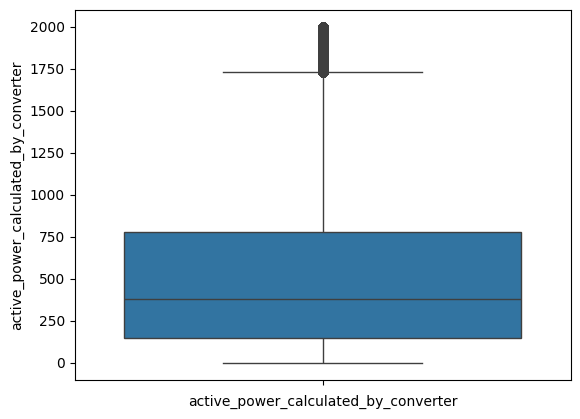

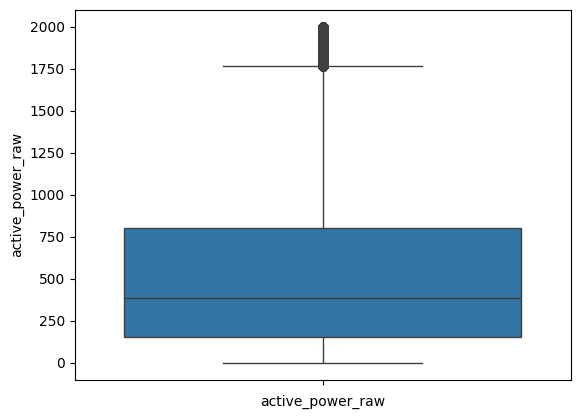

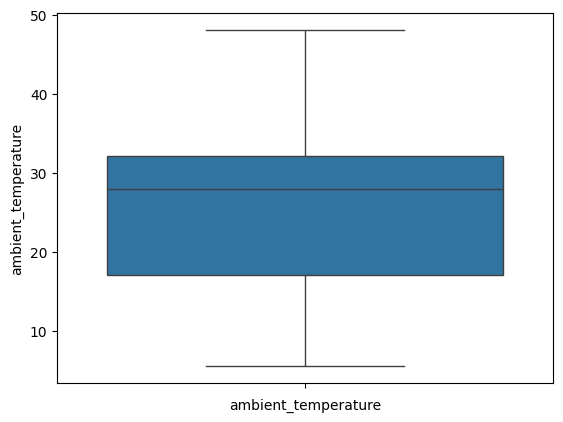

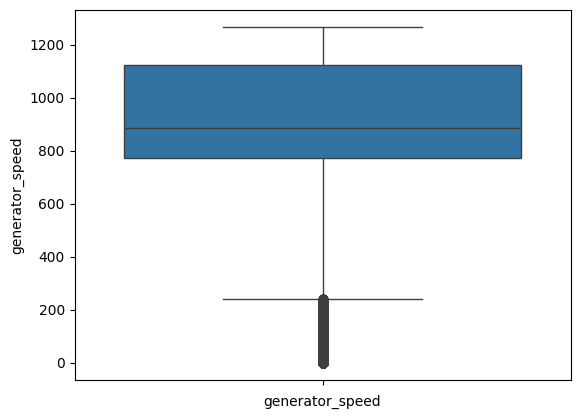

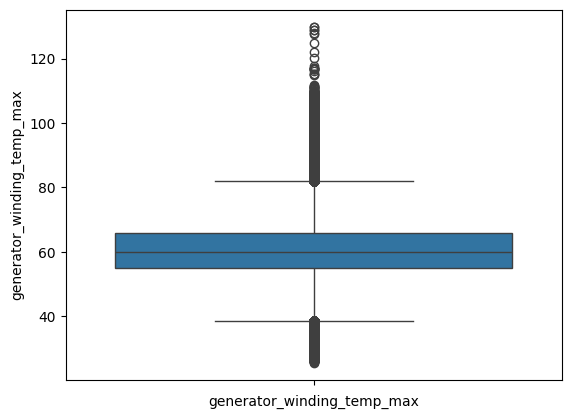

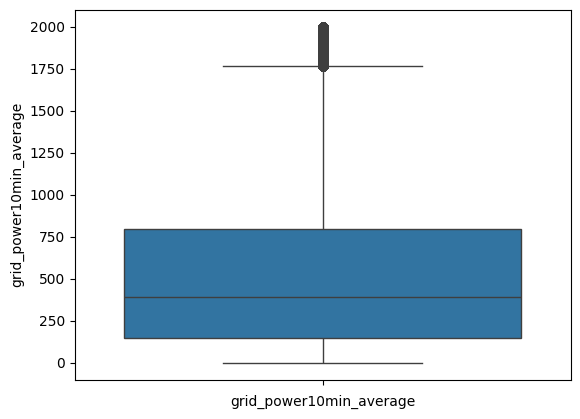

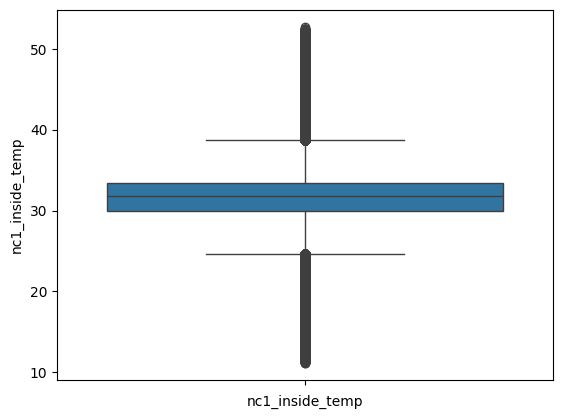

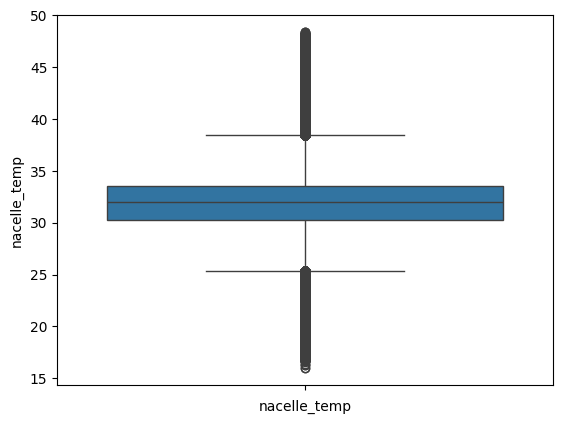

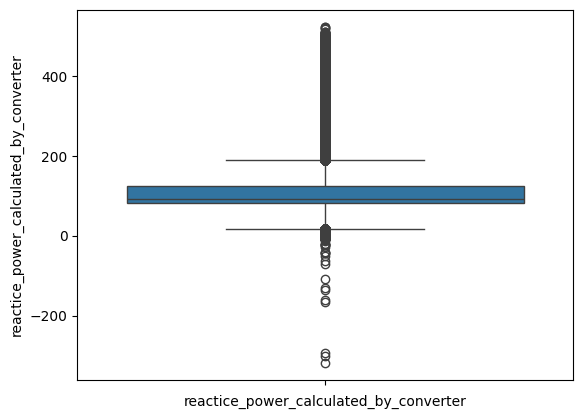

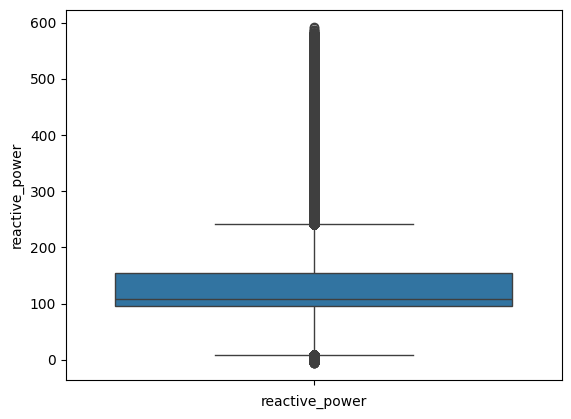

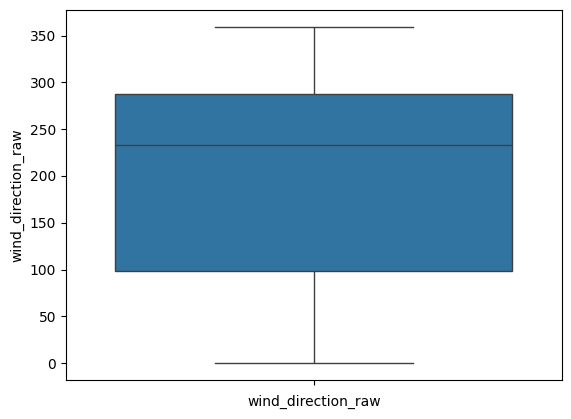

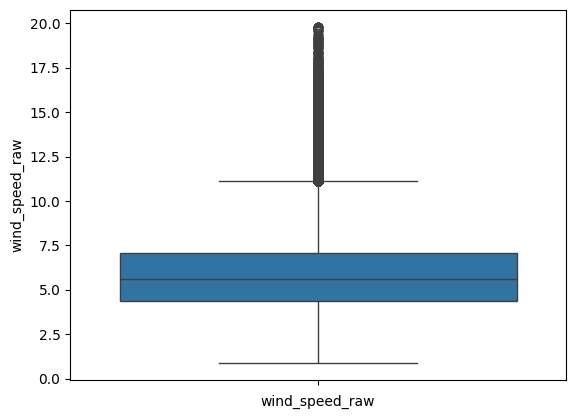

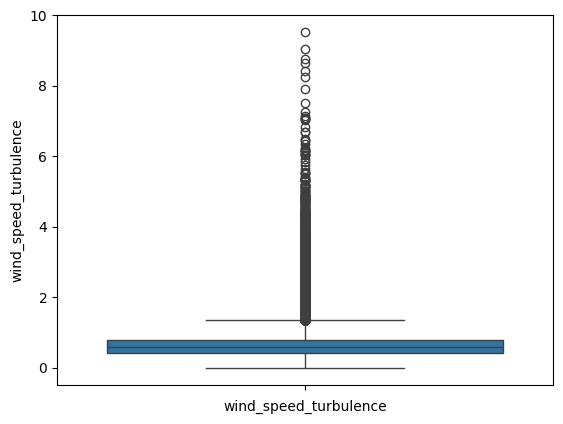

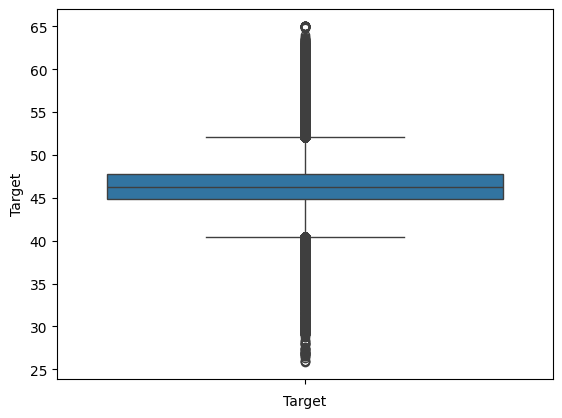

In [ ]:
for x in df.columns:
  if df[x].dtype!='object':
    sns.boxplot(df[x])
    plt.xlabel(x)
    plt.show()

### EDA Conclusion
* The dataset has over 900,000 entries with no missing numerical values.
* Boxplots reveal varying scales and several outliers in operational features like power, wind speeds, and temperatures. This indicates that standardizing/scaling features is necessary before training distance-sensitive models.

## 4. Data Cleaning & Feature Selection
We clean the data by dropping non-numeric/metadata columns such as identifiers and timestamps, and verify that there are no remaining missing values or duplicate records.

In [ ]:
df.drop(columns=['turbine_id','timestamp'],axis=1,inplace=True)

In [ ]:
df.isnull().sum()

,0
active_power_calculated_by_converter,0
active_power_raw,0
ambient_temperature,0
generator_speed,0
generator_winding_temp_max,0
grid_power10min_average,0
nc1_inside_temp,0
nacelle_temp,0
reactice_power_calculated_by_converter,0
reactive_power,0


In [ ]:
df.dropna

<bound method DataFrame.dropna of         active_power_calculated_by_converter  active_power_raw  \
0                                 816.636759        834.917206   
1                                 419.107829        421.050873   
2                                1303.530558       1337.566142   
3                                  61.494872         53.481008   
4                                 593.514364        611.659108   
...                                      ...               ...   
909599                            929.101908        948.441905   
909600                            100.730526         88.694599   
909601                           1120.915965       1165.016907   
909602                            123.444564        116.066919   
909603                              4.843147         10.779734   

        ambient_temperature  generator_speed  generator_winding_temp_max  \
0                 31.694380      1159.616602                   65.954214   
1                 12.894948       928.747996                   59.571319   
2                 16.648388      1201.219775                   61.270498   
3                 28.388141       769.806122                   40.674348   
4                 31.519527      1046.916768                   64.341763   
...                     ...              ...                         ...   
909599            32.736076      1187.303192                   83.187140   
909600            30.540500       770.245593                   56.235497   
909601            30.901129      1170.456860                   62.942943   
909602            32.697933       770.190796                   57.245207   
909603            19.452520       736.601664                   60.603885   

        grid_power10min_average  nc1_inside_temp  nacelle_temp  \
0                    917.897085        31.881972     31.504713   
1                    445.554250        32.423705     32.755770   
2                   1364.716003        11.446849     18.332985   
3                     14.324897        34.253204     32.662889   
4                    599.020172        32.405586     31.466387   
...                         ...              ...           ...   
909599              1343.320577        32.291391     35.152280   
909600               177.620552        30.434302     29.932141   
909601               873.414622        30.491818     33.085164   
909602                95.865704        32.338824     31.525384   
909603                78.559767        30.798932     38.252200   

        reactice_power_calculated_by_converter  reactive_power  \
0                                   141.457644      165.501518   
1                                    89.186457      113.835236   
2                                   230.622309      281.452253   
3                                    66.211015       75.017531   
4                                   137.163938      160.202421   
...                                        ...             ...   
909599                              152.216446      191.088800   
909600                               85.353107       96.621675   
909601                               42.820210       74.111173   
909602                               86.549094       97.470984   
909603                                2.763231        1.320198   

        wind_direction_raw  wind_speed_raw  wind_speed_turbulence     Target  
0               280.864782        7.057000               0.544082  47.582787  
1               299.552460        5.474937               0.469031  46.070328  
2                84.960106        8.092457               0.622318  39.989236  
3                87.261119        4.071032               0.760719  46.056587  
4               313.724818        6.357943               0.346068  54.346095  
...                    ...             ...                    ...        ...  
909599          189.901812        7.155343               1.028960  50.768675  
909600           93.417590        4.121607

In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df.duplicated().sum()

np.int64(0)

### Data Cleaning Conclusion
* Removing metadata columns (`turbine_id`, `timestamp`) restricts our dataset to strictly physical and environmental features.
* The clean dataset contains 14 columns, ready for correlation and collinearity filtering.

## 5. Multicollinearity Assessment & Feature Scaling (VIF)
Using the Variance Inflation Factor (VIF), we detect variables with excessive multicollinearity. Features with a VIF score greater than 10 are pruned to stabilize our model coefficients. We then scale the remaining features using standard scaling.

In [ ]:
# Define the independent variables (features), excluding the target variable
x = df.drop(columns=['Target'])
y = df['Target']

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['feature'] = x.columns
vif_data['VIF'] = [variance_inflation_factor(x.values, i) for i in range(len(x.columns))]

# Display the sorted VIF values
display(vif_data.sort_values(by='VIF', ascending=False))

,feature,VIF
0,active_power_calculated_by_converter,192.293479
1,active_power_raw,163.752729
9,reactive_power,136.180215
8,reactice_power_calculated_by_converter,109.041743
5,grid_power10min_average,14.060386
11,wind_speed_raw,8.616788
3,generator_speed,4.549658
4,generator_winding_temp_max,3.594684
7,nacelle_temp,3.267704
6,nc1_inside_temp,2.197839


In [ ]:
# Identify features with VIF > 10
high_vif_features = ['active_power_calculated_by_converter', 'active_power_raw', 'reactive_power', 'reactice_power_calculated_by_converter', 'grid_power10min_average']

# Drop these features from df
x.drop(columns=high_vif_features, inplace=True, errors='ignore')

In [ ]:
# Get the remaining features after dropping high VIF columns
features = x.columns

# Define and scale the feature matrix X_new using StandardScaler
scaler = StandardScaler()
X_new = scaler.fit_transform(x)

# Recalculate VIF to check the results using the scaled X_new array
vif_data_new = pd.DataFrame()
vif_data_new['feature'] = features
vif_data_new['VIF'] = [variance_inflation_factor(X_new, i) for i in range(len(features))]

display(vif_data_new.sort_values(by='VIF', ascending=False))

,feature,VIF
6,wind_speed_raw,4.205148
1,generator_speed,3.294021
4,nacelle_temp,2.928293
2,generator_winding_temp_max,2.337921
3,nc1_inside_temp,2.122251
7,wind_speed_turbulence,1.434493
0,ambient_temperature,1.165094
5,wind_direction_raw,1.040699


In [ ]:
X_new

array([[ 0.76261266,  1.17974221,  0.53737192, ...,  0.77786079,
         0.58758169, -0.33962021],
       [-1.57980742, -0.01230357, -0.11919807, ...,  0.9564899 ,
        -0.21237612, -0.57599023],
       [-1.11212664,  1.39455222,  0.05558621, ..., -1.09472487,
         1.11115266, -0.09321682],
       ...,
       [ 0.66377317,  1.23571381,  0.22762057, ...,  0.30110953,
         1.34334968,  0.94271824],
       [ 0.88765591, -0.83098328, -0.35847112, ..., -1.2816091 ,
        -0.79430629, -1.27421845],
       [-0.76273021, -1.00441432, -0.01298421, ..., -1.80046317,
        -1.96063042,  0.97984562]])

### Multicollinearity & VIF Conclusion
* The initial VIF analysis revealed extreme multicollinearity among power columns, with VIF values spanning up to hundreds of thousands.
* After pruning the highly collinear features (`active_power_calculated_by_converter`, `active_power_raw`, `reactive_power`, `reactice_power_calculated_by_converter`, `grid_power10min_average`), the maximum VIF among remaining features dropped below the critical threshold of 10. This ensures a much more stable and interpretable regression space.

## 6. Dataset Partitioning
We partition the scaled dataset into training and testing sets to properly evaluate model generalization performance.

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(X_new,y,test_size=0.2,random_state=42)

## 7. Model Development & Evaluation

### 7.1 Linear Regression Model
We train a baseline Linear Regression model and evaluate its accuracy using standard metrics.

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(x_train, y_train)

LinearRegression()

In [ ]:
# Predict on the test set
y_pred = lr.predict(x_test)

In [ ]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [ ]:

# Display the evaluation results
print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f}')
print(f'R-squared Score (R2): {r2:.4f}')

Mean Absolute Error (MAE): 1.4090
Mean Squared Error (MSE): 4.0727
Root Mean Squared Error (RMSE): 2.0181
R-squared Score (R2): 0.4036


### Linear Regression Conclusion
* The baseline Linear Regression model yields an **R-squared score of ~0.4036** and an **RMSE of ~2.0181**.
* This relatively low performance suggests that the relationships between our operational turbine features and the target variable are non-linear, warranting tree-based architectures.

### 7.2 Decision Tree Regressor
We train a non-linear Decision Tree model to capture potential non-linear relationships in our sensor inputs.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Initialize and train the Decision Tree Regressor
dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(x_train, y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
# Predict on the test set
y_pred_dt = dt_reg.predict(x_test)

In [ ]:
# Calculate evaluation metrics
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

In [ ]:
# Display the evaluation results
print(f'Decision Tree Regressor Metrics:')
print(f'Mean Absolute Error (MAE): {mae_dt:.4f}')
print(f'Mean Squared Error (MSE): {mse_dt:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse_dt:.4f}')
print(f'R-squared Score (R2): {r2_dt:.4f}')

Decision Tree Regressor Metrics:
Mean Absolute Error (MAE): 1.0647
Mean Squared Error (MSE): 3.6064
Root Mean Squared Error (RMSE): 1.8991
R-squared Score (R2): 0.4719


### Decision Tree Conclusion
* The single Decision Tree Regressor improves performance, yielding an **R-squared score of ~0.4719** and lower error metrics (**RMSE of ~1.8991**).
* Although better than Linear Regression, standalone decision trees are prone to overfitting, prompting the use of ensemble techniques.

### 7.3 Random Forest Regressor
Finally, we train an ensemble Random Forest Regressor using parallel jobs and structured tree constraints to achieve superior accuracy and prevent overfitting on this large scale dataset.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Initialize and train the Random Forest Regressor
# Note: With ~727k training samples, a limited max_depth and n_estimators helps it run efficiently.
rf_reg = RandomForestRegressor(n_estimators=100,
                               max_depth=15,
                               random_state=42,
                               n_jobs=-1)
rf_reg.fit(x_train, y_train)

RandomForestRegressor(max_depth=15, n_jobs=-1, random_state=42)

In [ ]:

# Predict on the test set
y_pred_rf = rf_reg.predict(x_test)

In [ ]:
# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

In [ ]:
# Display the evaluation results
print(f'Random Forest Regressor Metrics:')
print(f'Mean Absolute Error (MAE): {mae_rf:.4f}')
print(f'Mean Squared Error (MSE): {mse_rf:.4f}')
print(f'Root Mean Squared Error (RMSE): {rmse_rf:.4f}')
print(f'R-squared Score (R2): {r2_rf:.4f}')

Random Forest Regressor Metrics:
Mean Absolute Error (MAE): 0.9484
Mean Squared Error (MSE): 2.0902
Root Mean Squared Error (RMSE): 1.4458
R-squared Score (R2): 0.6939


### Random Forest Conclusion
* The Random Forest Regressor achieves the best overall performance, significantly pushing the **R-squared score to ~0.6939** and dropping the **RMSE to ~1.4458**.
* The ensemble of randomized trees successfully captured complex non-linear interactions across sensors while maintaining excellent generalizability across the 900k+ dataset rows.